# 05 · Crop model: deeper tests

Notebook 02 picked Random Forest without humidity (98.4% accuracy, one 5-fold CV). This notebook tests whether
we can do better, following the literature rather than intuition:

1. **Repeated CV and a proper significance test.** One 5-fold run is noisy. We use 5×5 repeated stratified CV and the
   corrected resampled t-test (Nadeau & Bengio, 2003), because folds share training data and a plain t-test overstates significance.
2. **Tuning** with nested CV (tuning inside each outer fold), so the tuned score isn't flattered by choosing on the test folds.
3. **Probability quality.** The ranker multiplies suitability by revenue, so the probabilities must mean what they say.
   Niculescu-Mizil & Caruana (2005) found boosted trees push probabilities away from 0 and 1 and that calibration
   (Platt/sigmoid or isotonic) fixes it. We measure log loss, Brier score and expected calibration error (ECE).
4. **Real-weather shift.** Many papers report 97–99% on this data with random splits, but none test on real farms
   (see `research/notes/2026-11-03_model_research.md`). Our Oct 29 check found NASA weather differs from Kaggle's
   (temperature ±3.2 °C, rainfall ×/÷ e^0.46). We perturb the test rows by that much and see which model holds up,
   and whether training on noise-augmented data helps.

Features: N, P, K, temperature, pH, rainfall (no humidity, as decided in 02). Seed 42 throughout.

In [1]:
import sys
sys.path.insert(0, '../project')
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, top_k_accuracy_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from xgboost import XGBClassifier

import data

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
RESULTS, FIGS = Path('../research/results'), Path('../research/figures')
FEATS = ['N', 'P', 'K', 'temperature', 'ph', 'rainfall']
crops = data.kaggle_crops()
enc = LabelEncoder()
X, y = crops[FEATS], enc.fit_transform(crops.label)
K = len(enc.classes_)
pd.set_option('display.width', 220)

In [2]:
def brier(y, p):
    """Multi-class Brier score: mean squared distance between the probability vector and the one-hot truth."""
    return np.mean(np.sum((p - np.eye(p.shape[1])[y]) ** 2, axis=1))


def ece(y, p, bins=15):
    """Expected calibration error of the top-1 probability (Guo et al., 2017)."""
    conf, pred = p.max(1), p.argmax(1)
    idx = np.minimum((conf * bins).astype(int), bins - 1)
    return sum(abs((pred[idx == b] == y[idx == b]).mean() - conf[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())


def scores(y, p):
    return {'accuracy': accuracy_score(y, p.argmax(1)), 'top3': top_k_accuracy_score(y, p, k=3, labels=range(K)),
            'log_loss': log_loss(y, np.clip(p, 1e-15, 1), labels=range(K)), 'brier': brier(y, p), 'ece': ece(y, p)}


def corrected_ttest(diffs, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test on per-fold score differences. Returns (mean, p-value)."""
    d = np.asarray(diffs)
    var = d.var(ddof=1) * (1 / len(d) + n_test / n_train)
    t = d.mean() / np.sqrt(var) if var > 0 else 0.0
    return d.mean(), 2 * stats.t.sf(abs(t), len(d) - 1)

## 1. Repeated CV: models and calibration

In [3]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
models = {
    'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'RandomForest': rf,
    'ExtraTrees': ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, random_state=SEED, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, random_state=SEED, n_jobs=4, verbose=-1),
    'RF + sigmoid': CalibratedClassifierCV(rf, method='sigmoid', cv=3),
    'RF + isotonic': CalibratedClassifierCV(rf, method='isotonic', cv=3),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
folds = list(rcv.split(X, y))

fold_rows = []
for name, model in models.items():
    for i, (tr, te) in enumerate(folds):
        p = clone(model).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])
        fold_rows.append({'model': name, 'fold': i, **scores(y[te], p)})
folds_df = pd.DataFrame(fold_rows)
summary = folds_df.groupby('model', sort=False).agg(['mean', 'std']).drop(columns='fold').round(4)
summary

accuracy            top3         log_loss           brier             ece        
                  mean     std    mean     std     mean     std    mean     std    mean     std
model                                                                                          
LogReg          0.9057  0.0108  0.9915  0.0047   0.3814  0.0176  0.1755  0.0088  0.1528  0.0096
RandomForest    0.9847  0.0060  1.0000  0.0000   0.0986  0.0097  0.0366  0.0064  0.0593  0.0066
ExtraTrees      0.9788  0.0056  1.0000  0.0000   0.1660  0.0090  0.0615  0.0052  0.1098  0.0071
XGBoost         0.9784  0.0068  0.9985  0.0021   0.0782  0.0199  0.0349  0.0090  0.0152  0.0044
LightGBM        0.9812  0.0059  0.9992  0.0014   0.1043  0.0424  0.0320  0.0097  0.0173  0.0056
RF + sigmoid    0.9852  0.0058  1.0000  0.0000   0.0994  0.0157  0.0276  0.0080  0.0545  0.0042
RF + isotonic   0.9844  0.0055  0.9979  0.0018   0.1096  0.0662  0.0264  0.0081  0.0132  0.0033

In [4]:
base = folds_df[folds_df.model == 'RandomForest'].set_index('fold')
n_te = len(folds[0][1]); n_tr = len(X) - n_te
tests = []
for name in models:
    if name == 'RandomForest':
        continue
    other = folds_df[folds_df.model == name].set_index('fold')
    for metric in ['accuracy', 'log_loss', 'ece']:
        diff, p = corrected_ttest(other[metric] - base[metric], n_tr, n_te)
        tests.append({'model': name, 'metric': metric, 'diff vs RF': round(diff, 4), 'p (corrected)': round(p, 4)})
tests = pd.DataFrame(tests).pivot(index='model', columns='metric', values=['diff vs RF', 'p (corrected)'])
tests

diff vs RF                  p (corrected)                 
metric          accuracy     ece log_loss      accuracy     ece log_loss
model                                                                   
ExtraTrees       -0.0059  0.0506   0.0673        0.0264  0.0000   0.0000
LightGBM         -0.0035 -0.0420   0.0057        0.2186  0.0000   0.7724
LogReg           -0.0790  0.0935   0.2828        0.0000  0.0000   0.0000
RF + isotonic    -0.0004 -0.0461   0.0110        0.7555  0.0000   0.7459
RF + sigmoid      0.0005 -0.0048   0.0008        0.6719  0.1099   0.8533
XGBoost          -0.0064 -0.0441  -0.0204        0.0988  0.0000   0.0173

Reliability diagram: when a model says 0.8, is it right 80% of the time? Out-of-fold predictions from the
first 5-fold repeat. Points below the diagonal are over-confident, above it under-confident.

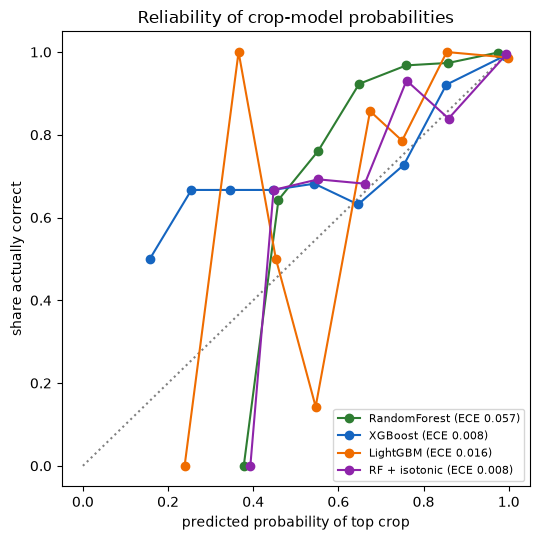

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color='grey', ls=':')
for name, col in [('RandomForest', '#2e7d32'), ('XGBoost', '#1565c0'), ('LightGBM', '#ef6c00'), ('RF + isotonic', '#8e24aa')]:
    P = np.zeros((len(X), K))
    for tr, te in folds[:5]:
        P[te] = clone(models[name]).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])
    conf, hit = P.max(1), P.argmax(1) == y
    b = pd.cut(conf, np.linspace(0, 1, 11))
    r = pd.DataFrame({'conf': conf, 'hit': hit}).groupby(b, observed=True).agg(conf=('conf', 'mean'), hit=('hit', 'mean'), n=('hit', 'size'))
    ax.plot(r.conf, r.hit, marker='o', color=col, label=f'{name} (ECE {ece(y, P):.3f})')
ax.set_xlabel('predicted probability of top crop')
ax.set_ylabel('share actually correct')
ax.set_title('Reliability of crop-model probabilities')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / 'crop_reliability.png', dpi=150)

## 2. Tuning with nested CV

In [6]:
grids = {
    'RandomForest': (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                     {'max_features': [1, 2, 3, 'sqrt'], 'min_samples_leaf': [1, 2, 4]}),
    'XGBoost': (XGBClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                {'max_depth': [3, 6], 'learning_rate': [0.05, 0.1]}),
    'LightGBM': (LGBMClassifier(n_estimators=300, random_state=SEED, n_jobs=4, verbose=-1),
                 {'num_leaves': [7, 15, 31], 'learning_rate': [0.05, 0.1]}),
}
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
nested = []
for name, (est, grid) in grids.items():
    for i, (tr, te) in enumerate(outer.split(X, y)):
        gs = GridSearchCV(est, grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring='neg_log_loss', n_jobs=1)
        gs.fit(X.iloc[tr], y[tr])
        nested.append({'model': name + ' (tuned)', 'fold': i, 'params': str(gs.best_params_),
                       **scores(y[te], gs.predict_proba(X.iloc[te]))})
nested = pd.DataFrame(nested)
print(nested.groupby('model')[['accuracy', 'top3', 'log_loss', 'ece']].mean().round(4))
print(nested.groupby('model').params.agg(lambda s: s.value_counts().index[0]).to_string())

                      accuracy    top3  log_loss     ece
model                                                   
LightGBM (tuned)        0.9818  0.9986    0.1148  0.0166
RandomForest (tuned)    0.9836  1.0000    0.0808  0.0375
XGBoost (tuned)         0.9791  0.9991    0.0775  0.0180
model
LightGBM (tuned)          {'learning_rate': 0.05, 'num_leaves': 7}
RandomForest (tuned)    {'max_features': 3, 'min_samples_leaf': 1}
XGBoost (tuned)             {'learning_rate': 0.1, 'max_depth': 3}


## 3. Real-weather shift

Noise sizes come from `research/results/2026-10-29_weather_vs_kaggle.csv` (8 crop–place pairs, yearly NASA means):
the SD of (NASA − Kaggle) for temperature, and the SD of log(NASA / Kaggle) for rainfall.

In [7]:
gap = pd.read_csv(RESULTS / '2026-10-29_weather_vs_kaggle.csv')
T_SD = (gap[gap.feature == 'temperature'].eval('nasa_year - kaggle')).std()
R_SD = np.log(gap[gap.feature == 'rainfall'].eval('nasa_year / kaggle')).std()
print(f'temperature noise SD {T_SD:.2f} °C, rainfall log-noise SD {R_SD:.3f} (×/÷ {np.exp(R_SD):.2f})')


def perturb(Xp, rng, scale=1.0):
    Xp = Xp.copy()
    Xp['temperature'] += rng.normal(0, T_SD * scale, len(Xp))
    Xp['rainfall'] *= np.exp(rng.normal(0, R_SD * scale, len(Xp)))
    return Xp


def augmented(model, copies=5):
    """Train on the clean rows plus `copies` noisy copies (noise injection as data augmentation)."""
    class Aug:
        def fit(self, Xa, ya):
            rng = np.random.default_rng(SEED)
            Xs = pd.concat([Xa] + [perturb(Xa, rng) for _ in range(copies)])
            self.m = clone(model).fit(Xs, np.tile(ya, copies + 1))
            return self
        def predict_proba(self, Xa):
            return self.m.predict_proba(Xa)
    return Aug()


shift_models = {k: models[k] for k in ['LogReg', 'RandomForest', 'ExtraTrees', 'XGBoost', 'LightGBM']}
shift_models['RF + noise augmentation'] = augmented(rf)
shift_models['LightGBM + noise augmentation'] = augmented(models['LightGBM'])

rows = []
for name, model in shift_models.items():
    for i, (tr, te) in enumerate(folds[:10]):  # 2 repeats × 5 folds keeps this to a few minutes
        m = (model if name.endswith('augmentation') else clone(model)).fit(X.iloc[tr], y[tr])
        for scale in [0, 0.5, 1.0]:
            p = m.predict_proba(perturb(X.iloc[te], np.random.default_rng(i), scale))
            rows.append({'model': name, 'fold': i, 'noise': scale, **scores(y[te], p)})
shift = pd.DataFrame(rows)
shift_tab = shift.pivot_table(index='model', columns='noise', values=['accuracy', 'top3'], aggfunc='mean').round(3)
shift_tab

temperature noise SD 3.15 °C, rainfall log-noise SD 0.461 (×/÷ 1.59)


accuracy                 top3              
noise                              0.0    0.5    1.0    0.0    0.5    1.0
model                                                                    
ExtraTrees                       0.979  0.895  0.767  1.000  0.995  0.973
LightGBM                         0.981  0.847  0.724  0.999  0.984  0.949
LightGBM + noise augmentation    0.867  0.862  0.855  0.997  0.996  0.995
LogReg                           0.902  0.810  0.653  0.992  0.976  0.903
RF + noise augmentation          0.936  0.916  0.889  0.999  0.998  0.997
RandomForest                     0.984  0.859  0.742  1.000  0.984  0.948
XGBoost                          0.980  0.829  0.715  0.998  0.968  0.931

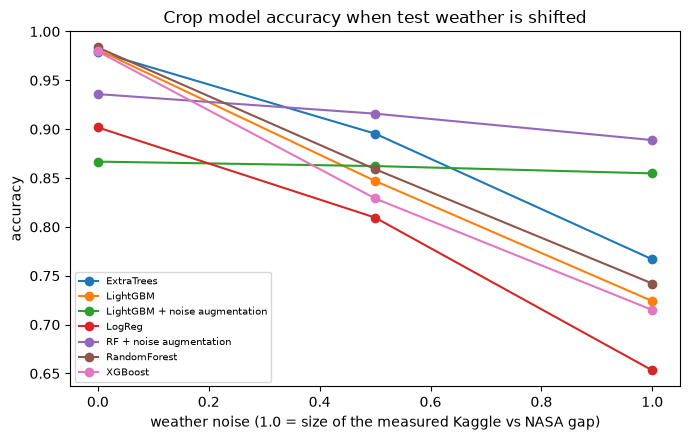

In [8]:
acc = shift.pivot_table(index='noise', columns='model', values='accuracy')
ax = acc.plot(marker='o', figsize=(7, 4.5))
ax.set_xlabel('weather noise (1.0 = size of the measured Kaggle vs NASA gap)')
ax.set_ylabel('accuracy')
ax.set_title('Crop model accuracy when test weather is shifted')
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / 'crop_weather_shift.png', dpi=150)

## 4. Save the tables

In [9]:
out = pd.concat([
    folds_df.drop(columns='fold').groupby('model', sort=False).mean().assign(test='5x5 repeated CV'),
    nested.drop(columns=['fold', 'params']).groupby('model').mean().assign(test='nested CV, tuned'),
    shift[shift.noise == 1.0].drop(columns=['fold', 'noise']).groupby('model').mean().assign(test='weather noise x1.0'),
]).round(4)
out.to_csv(RESULTS / '2026-11-03_crop_model_tests.csv')
out

,accuracy,top3,log_loss,brier,ece,test
model,,,,,,
LogReg,0.9057,0.9915,0.3814,0.1755,0.1528,5x5 repeated CV
RandomForest,0.9847,1.0000,0.0986,0.0366,0.0593,5x5 repeated CV
ExtraTrees,0.9788,1.0000,0.1660,0.0615,0.1098,5x5 repeated CV
XGBoost,0.9784,0.9985,0.0782,0.0349,0.0152,5x5 repeated CV
LightGBM,0.9812,0.9992,0.1043,0.0320,0.0173,5x5 repeated CV
RF + sigmoid,0.9852,1.0000,0.0994,0.0276,0.0545,5x5 repeated CV
RF + isotonic,0.9844,0.9979,0.1096,0.0264,0.0132,5x5 repeated CV
LightGBM (tuned),0.9818,0.9986,0.1148,0.0315,0.0166,"nested CV, tuned"
RandomForest (tuned),0.9836,1.0000,0.0808,0.0346,0.0375,"nested CV, tuned"


## 5. App model: noise augmentation + isotonic calibration

Sections 1 and 3 tested calibration and augmentation separately; the app uses both, so we test the combination on
the same 10 folds before saving it. The calibrator must be fitted on rows the forest didn't train on. With 5 noisy
copies of every row, a plain split would put copies of the same row on both sides, so the calibration folds keep each
row and its copies together (`StratifiedGroupKFold`). That also means the calibrator sees noisy rows, as the app will.
`ensemble=False`: one forest trained on all rows, which SHAP can explain directly.

In [10]:
def app_model(Xa, ya, copies=5):
    rng = np.random.default_rng(SEED)
    Xs = pd.concat([Xa] + [perturb(Xa, rng) for _ in range(copies)], ignore_index=True)
    ys, groups = np.tile(ya, copies + 1), np.tile(np.arange(len(Xa)), copies + 1)
    cal_folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(Xs, ys, groups))
    return CalibratedClassifierCV(clone(rf), method='isotonic', cv=cal_folds, ensemble=False).fit(Xs, ys)


rows = []
for i, (tr, te) in enumerate(folds[:10]):
    m = app_model(X.iloc[tr], y[tr])
    for scale in [0, 0.5, 1.0]:
        p = m.predict_proba(perturb(X.iloc[te], np.random.default_rng(i), scale))
        rows.append({'model': 'RF + noise augmentation + isotonic', 'fold': i, 'noise': scale, **scores(y[te], p)})
app = pd.concat([shift[shift.model.isin(['RandomForest', 'RF + noise augmentation'])], pd.DataFrame(rows)])
app_tab = app.pivot_table(index='model', columns='noise', values=['accuracy', 'top3', 'brier', 'ece'], aggfunc='mean').round(3)
app_tab.to_csv(RESULTS / '2026-11-03_crop_app_model.csv')
app_tab

accuracy                brier                  ece                 top3              
noise                                   0.0    0.5    1.0    0.0    0.5    1.0    0.0    0.5    1.0    0.0    0.5    1.0
model                                                                                                                   
RF + noise augmentation               0.936  0.916  0.889  0.111  0.135  0.169  0.076  0.074  0.063  0.999  0.998  0.997
RF + noise augmentation + isotonic    0.931  0.914  0.883  0.102  0.128  0.164  0.035  0.034  0.038  0.997  0.997  0.996
RandomForest                          0.984  0.859  0.742  0.037  0.223  0.388  0.059  0.084  0.078  1.000  0.984  0.948

In [11]:
base = app[(app.model == 'RF + noise augmentation') & (app.noise == 1.0)].set_index('fold')
cal = app[(app.model == 'RF + noise augmentation + isotonic') & (app.noise == 1.0)].set_index('fold')
n_te = len(folds[0][1]); n_tr = len(X) - n_te
for metric in ['accuracy', 'brier', 'ece']:
    diff, p = corrected_ttest(cal[metric] - base[metric], n_tr, n_te)
    print(f'{metric}: calibrated minus uncalibrated (weather noise x1.0) {diff:+.4f}, p = {p:.4f}')

accuracy: calibrated minus uncalibrated (weather noise x1.0) -0.0057, p = 0.1863
brier: calibrated minus uncalibrated (weather noise x1.0) -0.0058, p = 0.0689
ece: calibrated minus uncalibrated (weather noise x1.0) -0.0256, p = 0.0361


Train on all 2,200 rows and save for the app. `forest` is kept for SHAP.

In [12]:
final = app_model(X, y)
joblib.dump({'model': final, 'forest': final.calibrated_classifiers_[0].estimator, 'features': FEATS,
             'classes': list(enc.classes_)}, Path('../models/kaggle_crop_model.joblib'))
print('saved ../models/kaggle_crop_model.joblib')  # the app now uses the district model (notebook 09)

saved ../models/crop_model.joblib
